In [26]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/sandip83/creditcard/creditcard.csv


In [27]:
# ============================================================
# SECTION 1 — Load, clean, leakage-free split, scale
# Credit Card Fraud Detection (ULB dataset)
# ============================================================

# ============================================================
# CELL 0 — All imports. Run this FIRST, before anything else.
# ============================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    average_precision_score, roc_auc_score, confusion_matrix,
    precision_recall_curve,
)
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler

RANDOM_STATE = 42
print("All imports loaded.")

# ---- 1. Load ------------------------------------------------
df = pd.read_csv("/kaggle/input/datasets/sandip83/creditcard/creditcard.csv")
print("Raw shape:", df.shape)        # expect (284807, 31)

# ---- 2. Clean -----------------------------------------------
# Drop exact duplicate rows. There are 1081 in this dataset.
# Duplicates inflate the majority class and can leak identical
# rows into both train and test, flattering the scores.
n_before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Dropped {n_before - len(df)} duplicate rows; new shape: {df.shape}")

# Confirm no missing values (this dataset has none, but verify —
# never assume).
assert df.isnull().sum().sum() == 0, "Unexpected missing values"

# ---- 3. Separate features (X) and target (y) ----------------
X = df.drop(columns=["Class"])   # all 30 features: Time, V1..V28, Amount
y = df["Class"]                  # 0 = legitimate, 1 = fraud

print("Fraud rate: {:.4f}%".format(100 * y.mean()))
print("Imbalance ratio: {:.1f} : 1".format((y == 0).sum() / (y == 1).sum()))

# ---- 4. Stratified train/test split (BEFORE any scaling
#         or resampling — this is the leakage firewall) -------
# stratify=y keeps the fraud proportion identical in train and
# test. Without it, a random split can skew the ~0.17% fraud
# unevenly between the two sets.
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y,
)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Train fraud rate: {:.4f}%".format(100 * y_train.mean()))
print("Test  fraud rate: {:.4f}%".format(100 * y_test.mean()))

# ---- 5. Scale Time and Amount only --------------------------
# V1..V28 are already PCA outputs on a common scale, so we leave
# them. Time and Amount are on very different raw scales and need
# standardising. CRITICAL: fit the scaler on TRAIN ONLY, then
# apply to test. Fitting on all data would leak test-set
# statistics into training.
scale_cols = ["Time", "Amount"]
scaler = StandardScaler()

X_train = X_train.copy()   # avoid SettingWithCopyWarning
X_test  = X_test.copy()

X_train[scale_cols] = scaler.fit_transform(X_train[scale_cols])
X_test[scale_cols]  = scaler.transform(X_test[scale_cols])   # transform, NOT fit_transform

print("\nFoundation ready. X_train/X_test scaled, split is stratified and leakage-free.")

All imports loaded.
Raw shape: (284807, 31)
Dropped 1081 duplicate rows; new shape: (283726, 31)
Fraud rate: 0.1667%
Imbalance ratio: 598.8 : 1
Train: (226980, 30) | Test: (56746, 30)
Train fraud rate: 0.1665%
Test  fraud rate: 0.1674%

Foundation ready. X_train/X_test scaled, split is stratified and leakage-free.


In [28]:
# ============================================================
# SECTION 2 — Baseline model (Logistic Regression, NO balancing)
# Purpose: establish the honest floor and DEMONSTRATE the
# accuracy trap that motivates the rest of the project.
# ============================================================

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    average_precision_score, roc_auc_score, confusion_matrix,
    precision_recall_curve,
)

# ---- 1. Train a plain logistic regression, no class weighting.
# max_iter raised because the default (100) may not converge on
# this data. This is the "naive" model on purpose.
baseline = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
baseline.fit(X_train, y_train)

# ---- 2. Two kinds of prediction:
#   y_pred  = hard 0/1 labels at the DEFAULT 0.5 threshold
#   y_score = predicted PROBABILITY of fraud (needed for
#             PR-AUC, ROC-AUC, and later threshold optimisation)
y_pred  = baseline.predict(X_test)
y_score = baseline.predict_proba(X_test)[:, 1]

# ---- 3. Metrics ---------------------------------------------
acc    = accuracy_score(y_test, y_pred)
prec   = precision_score(y_test, y_pred)
rec    = recall_score(y_test, y_pred)
f1     = f1_score(y_test, y_pred)
pr_auc = average_precision_score(y_test, y_score)   # PR-AUC (primary-family metric)
roc    = roc_auc_score(y_test, y_score)             # ROC-AUC (for contrast)

print("=== Baseline: Logistic Regression, no balancing, 0.5 threshold ===")
print(f"Accuracy : {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall   : {rec:.4f}   <-- fraction of fraud actually caught")
print(f"F1-score : {f1:.4f}")
print(f"PR-AUC   : {pr_auc:.4f}   <-- threshold-independent, imbalance-aware")
print(f"ROC-AUC  : {roc:.4f}   <-- looks great even when recall is poor")

# ---- 4. Confusion matrix, raw counts ------------------------
tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
print(f"\nConfusion matrix (test set):")
print(f"  True negatives  (legit ok)     : {tn}")
print(f"  False positives (legit blocked): {fp}")
print(f"  False negatives (fraud MISSED) : {fn}   <-- the expensive ones")
print(f"  True positives  (fraud caught) : {tp}")


=== Baseline: Logistic Regression, no balancing, 0.5 threshold ===
Accuracy : 0.9991
Precision: 0.8485
Recall   : 0.5895   <-- fraction of fraud actually caught
F1-score : 0.6957
PR-AUC   : 0.6923   <-- threshold-independent, imbalance-aware
ROC-AUC  : 0.9563   <-- looks great even when recall is poor

Confusion matrix (test set):
  True negatives  (legit ok)     : 56641
  False positives (legit blocked): 10
  False negatives (fraud MISSED) : 39   <-- the expensive ones
  True positives  (fraud caught) : 56


In [29]:
# ============================================================
# SECTION 3 — The cost model
# This is the core of the thesis. Every downstream result
# (threshold optimisation, sensitivity analysis, the tool)
# is built on this function.
# ============================================================

# ---- Cost assumptions (STATE AND CITE THESE IN CHAPTER 3) ----
# Cost of a missed fraud (false negative) = the money lost on
#   that transaction PLUS a fixed admin cost (chargeback
#   handling, card reissue, investigation). The admin term also
#   ensures a missed ZERO-amount fraud still carries a real cost.
# Cost of a false decline (false positive) = a fixed friction
#   cost (support contact, customer inconvenience, churn risk),
#   independent of the transaction amount.
# Correct decisions (TN, TP) cost 0 in this misclassification
#   model. (A caught fraud may carry a small handling cost in
#   reality; we treat detection as the goal and set it to 0 —
#   note this simplification in the limitations.)

C_ADMIN = 20.0   # £ fixed admin cost per missed fraud (cite a source)

def expected_cost(y_true, y_pred, amounts, c_decline, c_admin=C_ADMIN):
    """
    Total expected misclassification cost on a set of predictions.

    y_true    : array of true labels (0 legit, 1 fraud)
    y_pred    : array of predicted labels (0/1) at some threshold
    amounts   : array of the ORIGINAL (unscaled) transaction Amount
                for each row, aligned with y_true / y_pred
    c_decline : £ cost of one false positive (false decline)
    c_admin   : £ fixed admin cost added to every missed fraud

    Returns total cost in £.
    """
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    amounts = np.asarray(amounts)

    # False negatives: true fraud (1) predicted legit (0)
    fn_mask = (y_true == 1) & (y_pred == 0)
    # False positives: true legit (0) predicted fraud (1)
    fp_mask = (y_true == 0) & (y_pred == 1)

    # Missed-fraud cost = sum of (amount + admin) over missed frauds
    fn_cost = np.sum(amounts[fn_mask] + c_admin)
    # False-decline cost = fixed cost × number of false declines
    fp_cost = c_decline * np.sum(fp_mask)

    return fn_cost + fp_cost


# ---- IMPORTANT: recover the ORIGINAL Amount for the test set ----
# X_test["Amount"] is now SCALED, so it is NOT the £ value.
# We need the real pounds. Pull them from the original df using
# the test set's index.
test_amounts = df.loc[X_test.index, "Amount"].values

# ---- Apply the cost model to the BASELINE predictions --------
# Try a single illustrative false-decline cost first.
c_decline_example = 20.0
baseline_cost = expected_cost(y_test, y_pred, test_amounts, c_decline_example)

# For context, compute the "do nothing" cost: a system that
# flags NOTHING pays the full fraud loss and zero decline cost.
do_nothing_pred = np.zeros_like(y_test)
do_nothing_cost = expected_cost(y_test, do_nothing_pred, test_amounts, c_decline_example)

print(f"Cost assumptions: C_admin=£{C_ADMIN:.0f}, C_decline=£{c_decline_example:.0f}")
print(f"Baseline model total cost on test set : £{baseline_cost:,.2f}")
print(f"'Flag nothing' total cost (reference)  : £{do_nothing_cost:,.2f}")
print(f"Baseline saves vs doing nothing        : £{do_nothing_cost - baseline_cost:,.2f}")

Cost assumptions: C_admin=£20, C_decline=£20
Baseline model total cost on test set : £9,736.14
'Flag nothing' total cost (reference)  : £16,666.31
Baseline saves vs doing nothing        : £6,930.17


=== Threshold optimisation (C_decline=£20) ===

Default 0.5 (t=0.500):
   Recall (fraud caught) : 0.5895  (56/95)
   False declines (FP)   : 10
   Missed frauds  (FN)   : 39
   Total cost            : £9,736.14

Cost-optimal (t=0.067):
   Recall (fraud caught) : 0.7684  (73/95)
   False declines (FP)   : 13
   Missed frauds  (FN)   : 22
   Total cost            : £4,741.31

Cost reduction from optimising threshold: £4,994.83


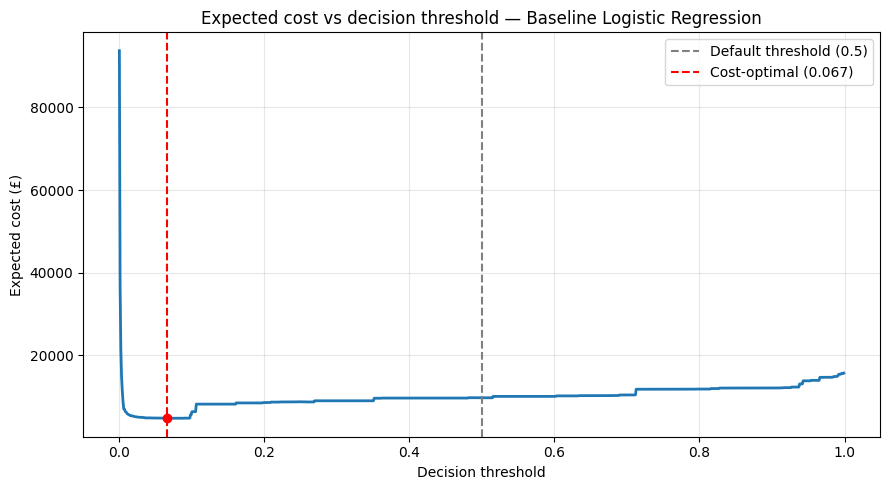

In [30]:
# ============================================================
# SECTION 4 — Threshold optimisation on the cost curve
# Instead of accepting the default 0.5 cutoff, we sweep every
# threshold and pick the one that MINIMISES expected cost.
# This is the operational heart of the thesis (Objective 5).
# ============================================================

# We reuse the baseline model's predicted probabilities (y_score)
# and the real-pound test_amounts from Section 3.

c_decline_example = 20.0   # hold the false-decline cost fixed for now

# ---- 1. Sweep thresholds from 0 to 1 ------------------------
# For each candidate threshold t, convert probabilities to 0/1
# labels (fraud if prob >= t), then compute the expected cost.
thresholds = np.linspace(0.001, 0.999, 999)
costs = []
for t in thresholds:
    y_pred_t = (y_score >= t).astype(int)
    c = expected_cost(y_test, y_pred_t, test_amounts, c_decline_example)
    costs.append(c)
costs = np.array(costs)

# ---- 2. Find the cost-minimising threshold ------------------
best_idx = np.argmin(costs)
best_threshold = thresholds[best_idx]
best_cost = costs[best_idx]

# ---- 3. Compare: default 0.5 vs cost-optimal ----------------
# Recompute the confusion matrix and recall at BOTH thresholds
# so we can see what optimisation actually changed.
def summarise(threshold):
    yp = (y_score >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, yp).ravel()
    rec = tp / (tp + fn)
    cost = expected_cost(y_test, yp, test_amounts, c_decline_example)
    return threshold, rec, fp, fn, tp, cost

print("=== Threshold optimisation (C_decline=£20) ===\n")
for label, thr in [("Default 0.5", 0.5), ("Cost-optimal", best_threshold)]:
    t, rec, fp, fn, tp, cost = summarise(thr)
    print(f"{label} (t={t:.3f}):")
    print(f"   Recall (fraud caught) : {rec:.4f}  ({tp}/{tp+fn})")
    print(f"   False declines (FP)   : {fp}")
    print(f"   Missed frauds  (FN)   : {fn}")
    print(f"   Total cost            : £{cost:,.2f}\n")

print(f"Cost reduction from optimising threshold: "
      f"£{summarise(0.5)[5] - best_cost:,.2f}")

# ---- 4. Plot the cost curve (this is a Chapter 4 figure) ----
plt.figure(figsize=(9, 5))
plt.plot(thresholds, costs, linewidth=2)
plt.axvline(0.5, linestyle="--", color="grey", label="Default threshold (0.5)")
plt.axvline(best_threshold, linestyle="--", color="red",
            label=f"Cost-optimal ({best_threshold:.3f})")
plt.scatter([best_threshold], [best_cost], color="red", zorder=5)
plt.xlabel("Decision threshold")
plt.ylabel("Expected cost (£)")
plt.title("Expected cost vs decision threshold — Baseline Logistic Regression")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [31]:
# ============================================================
# SECTION 5 — Full model grid with LEAKAGE-FREE threshold choice
# 3 models x 3 balancing techniques.
# Threshold chosen on VALIDATION, reported once on TEST.
# ============================================================
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler

# ---- 1. Three-way split -------------------------------------
# Carve a validation set OUT OF the training data. Test stays
# untouched. Stratify every split to preserve the fraud ratio.
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train, test_size=0.25,          # 0.25 of 80% = 20% of all
    random_state=RANDOM_STATE, stratify=y_train,
)
# Real-pound amounts for validation and test (for the cost model)
val_amounts  = df.loc[X_val.index,  "Amount"].values
# test_amounts already defined in Section 3

print(f"Train: {X_tr.shape[0]} | Val: {X_val.shape[0]} | Test: {X_test.shape[0]}")

# ---- 2. Define models and balancing techniques --------------
models = {
    "LogReg": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "RandomForest": RandomForestClassifier(n_estimators=100, n_jobs=-1,
                                           random_state=RANDOM_STATE),
    "HistGB": HistGradientBoostingClassifier(random_state=RANDOM_STATE),
}

def make_balancer(name):
    # Returns a resampler, or None for class_weight / none
    if name == "under":  return RandomUnderSampler(random_state=RANDOM_STATE)
    if name == "smote":  return SMOTE(random_state=RANDOM_STATE)
    return None  # "weight" and "none" handled via class_weight below

techniques = ["none", "weight", "under", "smote"]

# ---- 3. Helper: choose cost-optimal threshold ON VALIDATION --
def best_threshold_on_val(model, c_decline):
    val_scores = model.predict_proba(X_val)[:, 1]
    ts = np.linspace(0.001, 0.999, 999)
    costs = [expected_cost(y_val, (val_scores >= t).astype(int),
                           val_amounts, c_decline) for t in ts]
    return ts[int(np.argmin(costs))]

# ---- 4. Train every combination, evaluate ONCE on test -------
C_DECLINE = 20.0
results = []
for m_name, base_model in models.items():
    for tech in techniques:
        # clone a fresh model each time
        from sklearn.base import clone
        model = clone(base_model)

        # apply balancing
        if tech == "weight":
            if "class_weight" in model.get_params():
                model.set_params(class_weight="balanced")
            X_fit, y_fit = X_tr, y_tr
        elif tech in ("under", "smote"):
            # RESAMPLE ONLY THE TRAINING DATA — never val or test
            sampler = make_balancer(tech)
            X_fit, y_fit = sampler.fit_resample(X_tr, y_tr)
        else:  # none
            X_fit, y_fit = X_tr, y_tr

        model.fit(X_fit, y_fit)

        # threshold chosen on validation (leakage-free)
        thr = best_threshold_on_val(model, C_DECLINE)

        # report ONCE on the untouched test set
        test_scores = model.predict_proba(X_test)[:, 1]
        y_pred_test = (test_scores >= thr).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_test, y_pred_test).ravel()
        results.append({
            "model": m_name, "technique": tech, "threshold": round(thr, 3),
            "recall": round(tp/(tp+fn), 4),
            "precision": round(tp/(tp+fp), 4) if (tp+fp) else 0,
            "false_declines": fp, "missed_frauds": fn,
            "pr_auc": round(average_precision_score(y_test, test_scores), 4),
            "cost": round(expected_cost(y_test, y_pred_test, test_amounts, C_DECLINE), 2),
        })

results_df = pd.DataFrame(results).sort_values("cost").reset_index(drop=True)
print(results_df.to_string(index=False))

Train: 170235 | Val: 56745 | Test: 56746


KeyboardInterrupt: 